In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv('../data/raw/smart_meter_data.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df = df.sort_values('Timestamp').reset_index(drop=True)

print(f"Размер датасета: {df.shape}")
print(f"Период: с {df['Timestamp'].min()} по {df['Timestamp'].max()}")
df.head()

Размер датасета: (5000, 7)
Период: с 2024-01-01 00:00:00 по 2024-04-14 03:30:00


,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label
0,2024-01-01 00:00:00,0.457786,0.469524,0.396368,0.445441,0.692057,Normal
1,2024-01-01 00:30:00,0.351956,0.465545,0.451184,0.458729,0.539874,Normal
2,2024-01-01 01:00:00,0.482948,0.285415,0.408289,0.470360,0.614724,Normal
3,2024-01-01 01:30:00,0.628838,0.482095,0.512308,0.576241,0.757044,Normal
4,2024-01-01 02:00:00,0.335974,0.624741,0.672021,0.373004,0.673981,Normal


In [5]:
print("### Информация о датасете ###\n")
df.info()

print("\n### Пропуски ###\n")
print(df.isnull().sum())

print("\n### Дубликаты ###\n")
print(f"Количество дубликатов: {df.duplicated().sum()}")

print("\n### Описание ###\n")
df.describe()

### Информация о датасете ###

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Timestamp             5000 non-null   datetime64[ns]
 1   Electricity_Consumed  5000 non-null   float64       
 2   Temperature           5000 non-null   float64       
 3   Humidity              5000 non-null   float64       
 4   Wind_Speed            5000 non-null   float64       
 5   Avg_Past_Consumption  5000 non-null   float64       
 6   Anomaly_Label         5000 non-null   object        
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 273.6+ KB

### Пропуски ###

Timestamp               0
Electricity_Consumed    0
Temperature             0
Humidity                0
Wind_Speed              0
Avg_Past_Consumption    0
Anomaly_Label           0
dtype: int64

### Дубликаты ###

Количество дубликатов: 0

### Опис

,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2024-02-22 01:45:00.000000256,0.376677,0.525069,0.497632,0.464628,0.458738
min,2024-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2024-01-27 00:52:30,0.265349,0.434253,0.398956,0.382906,0.358857
50%,2024-02-22 01:45:00,0.377244,0.524052,0.497539,0.464958,0.457814
75%,2024-03-19 02:37:30,0.486002,0.617281,0.595359,0.547419,0.555607
max,2024-04-14 03:30:00,1.000000,1.000000,1.000000,1.000000,1.000000
std,NaN,0.164117,0.135603,0.146781,0.120370,0.146749


In [9]:
print("### Распределение классов ###\n")
print(df['Anomaly_Label'].value_counts())
print(f"\nДоля аномалий: {(df['Anomaly_Label'] == 'Abnormal').mean() * 100:.2f}%")

### Распределение классов ###

Anomaly_Label
Normal      4750
Abnormal     250
Name: count, dtype: int64

Доля аномалий: 5.00%


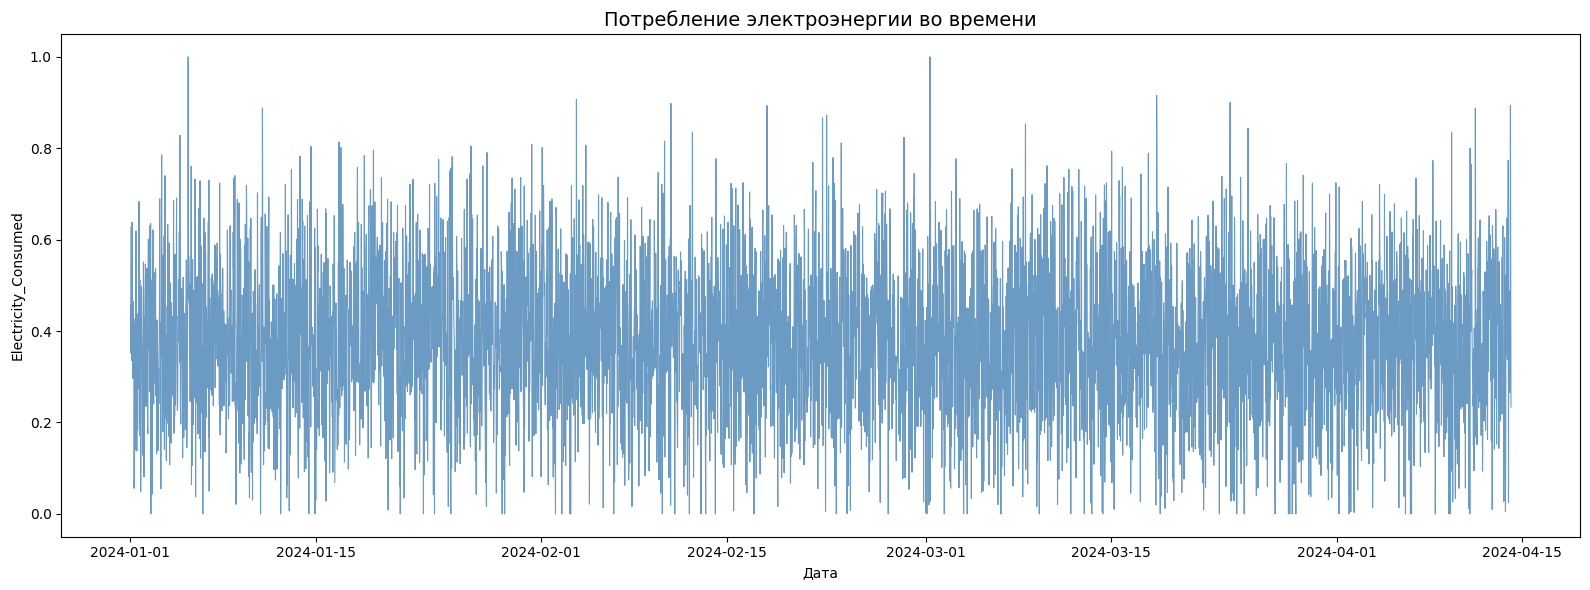

In [7]:
fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(df['Timestamp'], df['Electricity_Consumed'], 
        linewidth=0.8, alpha=0.8, color='steelblue')
ax.set_title('Потребление электроэнергии во времени', fontsize=14)
ax.set_xlabel('Дата')
ax.set_ylabel('Electricity_Consumed')
plt.tight_layout()
plt.savefig('../reports/figures/01_timeseries.png', dpi=150)
plt.show()

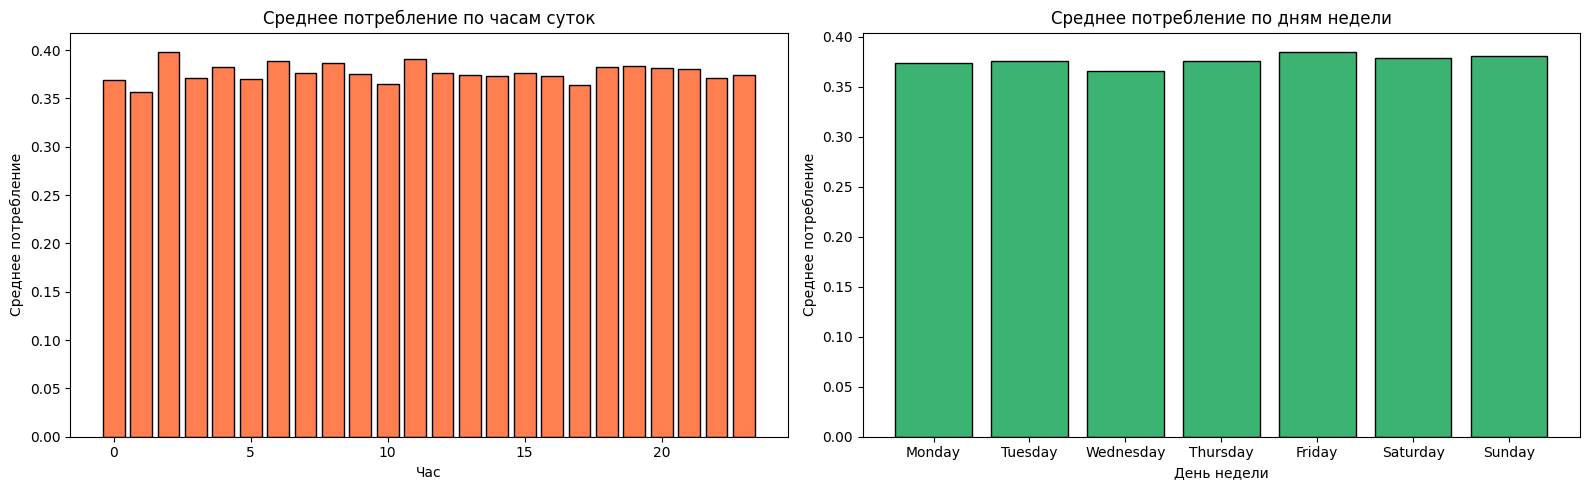

In [10]:
df['hour'] = df['Timestamp'].dt.hour
df['day_name'] = df['Timestamp'].dt.day_name()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

hourly = df.groupby('hour')['Electricity_Consumed'].mean()
axes[0].bar(hourly.index, hourly.values, color='coral', edgecolor='black')
axes[0].set_title('Среднее потребление по часам суток')
axes[0].set_xlabel('Час')
axes[0].set_ylabel('Среднее потребление')

order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
daily = df.groupby('day_name')['Electricity_Consumed'].mean().reindex(order)
axes[1].bar(daily.index, daily.values, color='mediumseagreen', edgecolor='black')
axes[1].set_title('Среднее потребление по дням недели')
axes[1].set_xlabel('День недели')
axes[1].set_ylabel('Среднее потребление')

plt.tight_layout()
plt.savefig('../reports/figures/02_seasonality.png', dpi=150)
plt.show()

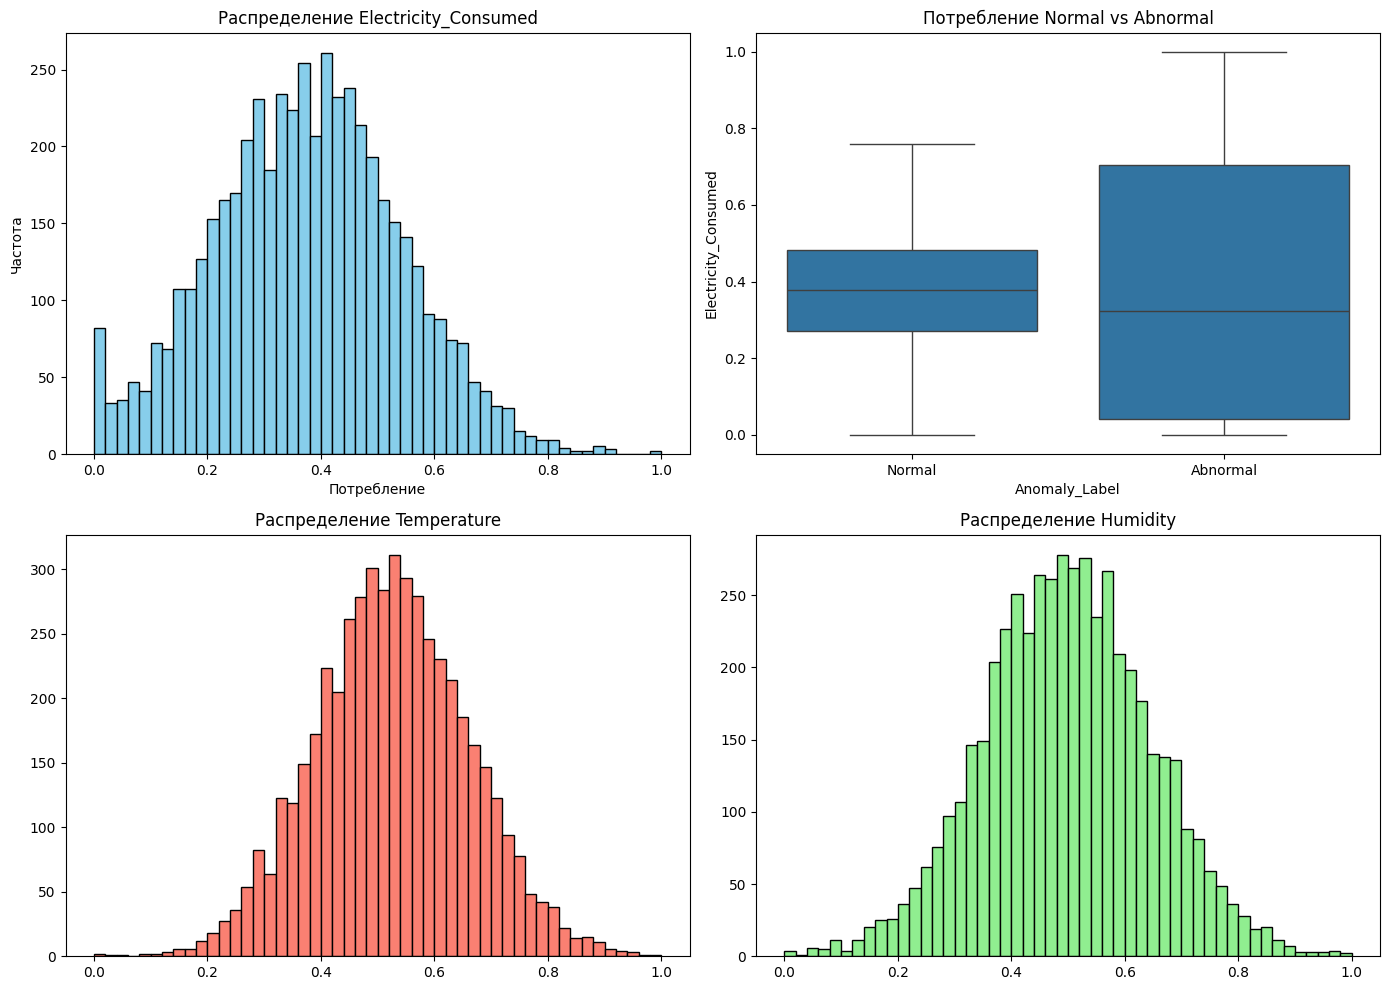

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0,0].hist(df['Electricity_Consumed'], bins=50, color='skyblue', edgecolor='black')
axes[0,0].set_title('Распределение Electricity_Consumed')
axes[0,0].set_xlabel('Потребление')
axes[0,0].set_ylabel('Частота')

sns.boxplot(x='Anomaly_Label', y='Electricity_Consumed', data=df, ax=axes[0,1])
axes[0,1].set_title('Потребление Normal vs Abnormal')

axes[1,0].hist(df['Temperature'], bins=50, color='salmon', edgecolor='black')
axes[1,0].set_title('Распределение Temperature')

axes[1,1].hist(df['Humidity'], bins=50, color='lightgreen', edgecolor='black')
axes[1,1].set_title('Распределение Humidity')

plt.tight_layout()
plt.savefig('../reports/figures/03_distributions.png', dpi=150)
plt.show()

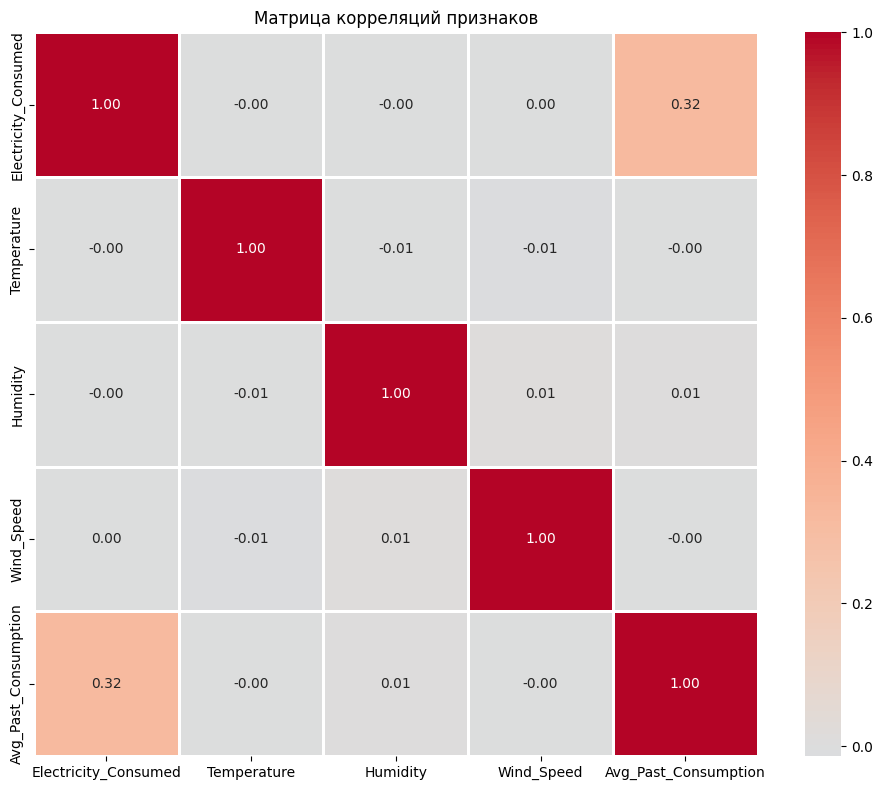

Electricity_Consumed    1.000000
Avg_Past_Consumption    0.316663
Wind_Speed              0.001342
Humidity               -0.002916
Temperature            -0.003440
Name: Electricity_Consumed, dtype: float64


In [13]:
numeric_cols = ['Electricity_Consumed', 'Temperature', 'Humidity', 
                'Wind_Speed', 'Avg_Past_Consumption']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            fmt='.2f', square=True, linewidths=1)
plt.title('Матрица корреляций признаков')
plt.tight_layout()
plt.savefig('../reports/figures/04_correlations.png', dpi=150)
plt.show()

print(corr_matrix['Electricity_Consumed'].sort_values(ascending=False))

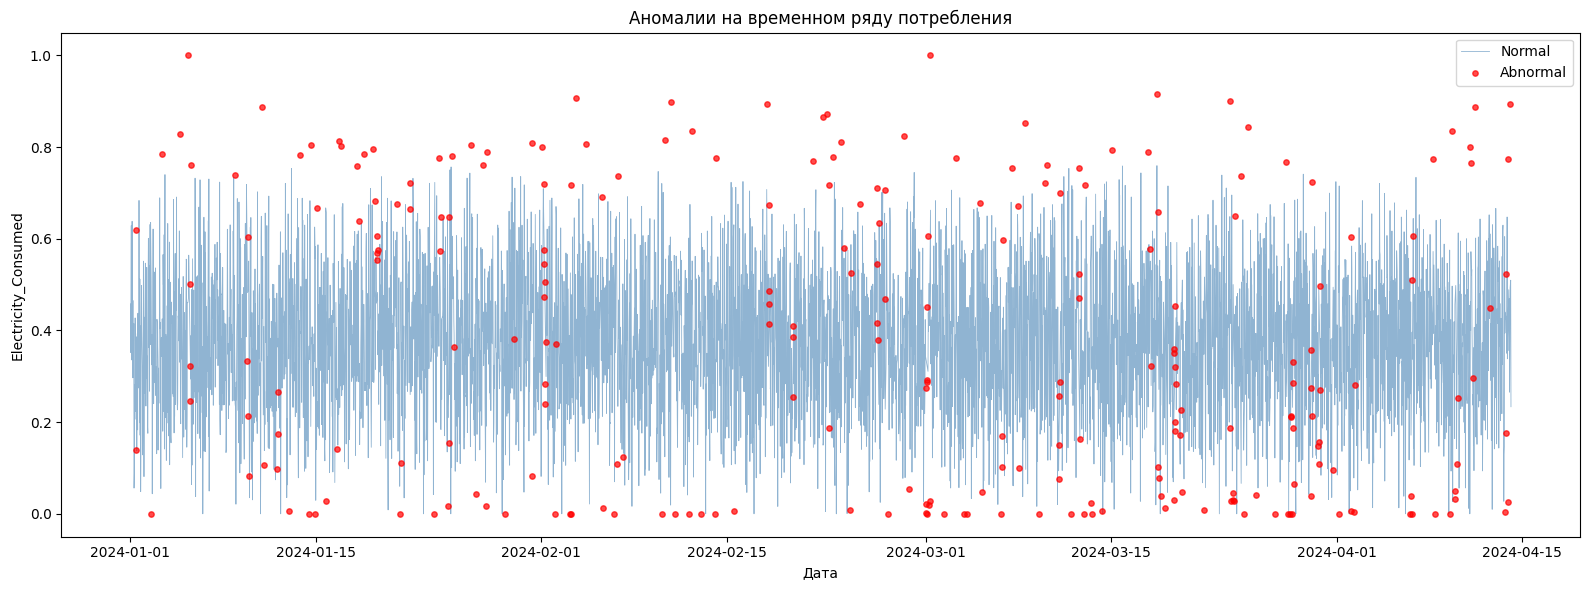

In [14]:
fig, ax = plt.subplots(figsize=(16, 6))
normal = df[df['Anomaly_Label'] == 'Normal']
abnormal = df[df['Anomaly_Label'] == 'Abnormal']

ax.plot(normal['Timestamp'], normal['Electricity_Consumed'], 
        linewidth=0.6, alpha=0.6, color='steelblue', label='Normal')
ax.scatter(abnormal['Timestamp'], abnormal['Electricity_Consumed'], 
           color='red', s=15, alpha=0.7, label='Abnormal', zorder=5)
ax.set_title('Аномалии на временном ряду потребления')
ax.set_xlabel('Дата')
ax.set_ylabel('Electricity_Consumed')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/05_anomalies.png', dpi=150)
plt.show()